# Real-Time UPI Fraud Detection
## 02 — Supervised Machine Learning

### Objective
Build and compare supervised classification models to identify potentially fraudulent UPI transactions.

**Models:** Logistic Regression, Random Forest, XGBoost

**Key Challenges:**
- Extreme class imbalance (0.192% fraud)
- Data leakage prevention
- Model evaluation beyond accuracy
- Cost-aware model selection

**Workflow:** Data loading → Splitting → Preprocessing → Baselines → Model training → Imbalance handling → Evaluation → Model selection

**Random Seed:** 42

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

SEED = 42

# Locate the dataset from the repository
data_path = Path("data/upi_eda_ready.csv")

if not data_path.exists():
    data_path = Path("../data/upi_eda_ready.csv")

df = pd.read_csv(
    data_path,
    parse_dates=["timestamp"]
)

print("Dataset shape:", df.shape)
print("Date range:", df["timestamp"].min(), "to", df["timestamp"].max())

print("\nFraud distribution:")
print(df["fraud_flag"].value_counts())

print("\nFraud rate:")
print(f"{df['fraud_flag'].mean() * 100:.4f}%")

assert df["fraud_flag"].isin([0, 1]).all()
assert df["transaction id"].is_unique

display(df.head())

Dataset shape: (250000, 18)
Date range: 2024-01-01 00:05:10 to 2024-12-30 23:55:40

Fraud distribution:
fraud_flag
0    249520
1       480
Name: count, dtype: int64

Fraud rate:
0.1920%


,transaction id,timestamp,transaction type,merchant_category,amount (INR),transaction_status,sender_age_group,receiver_age_group,sender_state,sender_bank,receiver_bank,device_type,network_type,fraud_flag,hour_of_day,day_of_week,is_weekend,month
0,TXN0000000001,2024-10-08 15:17:28,P2P,Entertainment,868,SUCCESS,26-35,18-25,Delhi,Axis,SBI,Android,4G,0,15,Tuesday,0,10
1,TXN0000000002,2024-04-11 06:56:00,P2M,Grocery,1011,SUCCESS,26-35,26-35,Uttar Pradesh,ICICI,Axis,iOS,4G,0,6,Thursday,0,4
2,TXN0000000003,2024-04-02 13:27:18,P2P,Grocery,477,SUCCESS,26-35,36-45,Karnataka,Yes Bank,PNB,Android,4G,0,13,Tuesday,0,4
3,TXN0000000004,2024-01-07 10:09:17,P2P,Fuel,2784,SUCCESS,26-35,26-35,Delhi,ICICI,PNB,Android,5G,0,10,Sunday,1,1
4,TXN0000000005,2024-01-23 19:04:23,P2P,Shopping,990,SUCCESS,26-35,18-25,Delhi,Axis,Yes Bank,iOS,WiFi,0,19,Tuesday,0,1


## Chronological Train / Validation / Test Split

Transactions are sorted by timestamp to simulate real-world fraud detection.

- Training: Oldest 70% of transactions
- Validation: Next 15% of transactions
- Testing: Latest 15% of transactions

We will examine fraud counts, fraud rates, and date boundaries before finalizing the split.

In [18]:
# Sort transactions chronologically
df_sorted = df.sort_values(
    ["timestamp", "transaction id"]
).reset_index(drop=True)

# Split boundaries
n = len(df_sorted)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

# Create chronological partitions
train_df = df_sorted.iloc[:train_end].copy()
val_df = df_sorted.iloc[train_end:val_end].copy()
test_df = df_sorted.iloc[val_end:].copy()

# Summarize each partition
split_summary = []

for name, subset in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    split_summary.append({
        "Split": name,
        "Transactions": len(subset),
        "Genuine": (subset["fraud_flag"] == 0).sum(),
        "Fraud": (subset["fraud_flag"] == 1).sum(),
        "Fraud Rate (%)": round(
            subset["fraud_flag"].mean() * 100, 4
        ),
        "Start Date": subset["timestamp"].min(),
        "End Date": subset["timestamp"].max()
    })

split_summary = pd.DataFrame(split_summary)

display(split_summary)

print("Total transactions:", split_summary["Transactions"].sum())
print("Total frauds:", split_summary["Fraud"].sum())

,Split,Transactions,Genuine,Fraud,Fraud Rate (%),Start Date,End Date
0,Train,175000,174675,325,0.1857,2024-01-01 00:05:10,2024-09-12 17:03:58
1,Validation,37500,37412,88,0.2347,2024-09-12 17:04:19,2024-11-06 07:06:12
2,Test,37500,37433,67,0.1787,2024-11-06 07:09:06,2024-12-30 23:55:40


Total transactions: 250000
Total frauds: 480


### Final Splitting Decision: Chronological 70/15/15

We selected chronological splitting to simulate real-world
fraud detection using historical transactions.

| Split | Transactions | Fraud | Fraud Rate |
|---|---:|---:|---:|
| Train | 175,000 | 325 | 0.1857% |
| Validation | 37,500 | 88 | 0.2347% |
| Test | 37,500 | 67 | 0.1787% |

**Decision:** Accept the chronological split.

- No random shuffling was applied.
- Every partition contains genuine and fraudulent transactions.
- SMOTE and other learned transformations will use training data only.
- Validation will support model selection and threshold tuning.
- Test data will remain untouched until final evaluation.

The same partitions will be shared with the anomaly detection team.

In [19]:
from pathlib import Path

# Confirm unique, non-overlapping partitions
train_ids = set(train_df["transaction id"])
val_ids = set(val_df["transaction id"])
test_ids = set(test_df["transaction id"])

assert not train_ids & val_ids
assert not train_ids & test_ids
assert not val_ids & test_ids

assert len(train_ids | val_ids | test_ids) == len(df)

assert train_df["timestamp"].max() < val_df["timestamp"].min()
assert val_df["timestamp"].max() < test_df["timestamp"].min()

# Save the shared split mapping
split_mapping = pd.concat([
    train_df[["transaction id"]].assign(split="train"),
    val_df[["transaction id"]].assign(split="validation"),
    test_df[["transaction id"]].assign(split="test")
])

output_dir = Path("../data") if Path("../data").exists() else Path("data")
output_dir.mkdir(parents=True, exist_ok=True)

split_mapping.to_csv(
    output_dir / "upi_split_mapping.csv",
    index=False
)

print("Chronological split validated successfully!")
print(split_mapping["split"].value_counts())

Chronological split validated successfully!
split
train         175000
validation     37500
test           37500
Name: count, dtype: int64


In [20]:
# Define feature groups

numeric_features = [
    "amount (INR)",
    "hour_of_day",
    "month"
]

categorical_features = [
    "transaction type",
    "merchant_category",
    "sender_age_group",
    "receiver_age_group",
    "sender_state",
    "sender_bank",
    "receiver_bank",
    "device_type",
    "network_type",
    "day_of_week"
]

binary_features = [
    "is_weekend"
]

feature_cols = (
    numeric_features +
    categorical_features +
    binary_features
)

target_col = "fraud_flag"

# Validate feature configuration
assert len(feature_cols) == 14
assert len(feature_cols) == len(set(feature_cols))
assert all(col in df.columns for col in feature_cols)

# Prepare X and y for each chronological partition
X_train = train_df[feature_cols].copy()
X_val = val_df[feature_cols].copy()
X_test = test_df[feature_cols].copy()

y_train = train_df[target_col].copy()
y_val = val_df[target_col].copy()
y_test = test_df[target_col].copy()

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Binary features:", len(binary_features))

print("\nDataset shapes:")
print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_val:  ", X_val.shape, "y_val:  ", y_val.shape)
print("X_test: ", X_test.shape, "y_test: ", y_test.shape)

Numerical features: 3
Categorical features: 10
Binary features: 1

Dataset shapes:
X_train: (175000, 14) y_train: (175000,)
X_val:   (37500, 14) y_val:   (37500,)
X_test:  (37500, 14) y_test:  (37500,)


In [21]:
# Calculate high-amount threshold from training data only
Q1 = X_train["amount (INR)"].quantile(0.25)
Q3 = X_train["amount (INR)"].quantile(0.75)

high_amount_threshold = Q3 + 1.5 * (Q3 - Q1)

print("Training-only high amount threshold:",
      high_amount_threshold)


def engineer_features(X, threshold):
    X = X.copy()

    # 1. Log transformation
    X["log_amount"] = np.log1p(X["amount (INR)"])

    # 2. High amount indicator
    X["is_high_amount"] = (
        X["amount (INR)"] > threshold
    ).astype(int)

    # 3. Cyclical hour encoding
    X["hour_sin"] = np.sin(
        2 * np.pi * X["hour_of_day"] / 24
    )

    X["hour_cos"] = np.cos(
        2 * np.pi * X["hour_of_day"] / 24
    )

    # 4. Same-bank indicator
    X["same_bank"] = (
        X["sender_bank"] == X["receiver_bank"]
    ).astype(int)

    return X


# Engineer features separately for each partition
X_train_fe = engineer_features(
    X_train, high_amount_threshold
)

X_val_fe = engineer_features(
    X_val, high_amount_threshold
)

X_test_fe = engineer_features(
    X_test, high_amount_threshold
)

print("Baseline shape:", X_train.shape)
print("Engineered shape:", X_train_fe.shape)

display(
    X_train_fe[
        [
            "amount (INR)",
            "log_amount",
            "is_high_amount",
            "hour_sin",
            "hour_cos",
            "same_bank"
        ]
    ].head()
)

Training-only high amount threshold: 3551.5
Baseline shape: (175000, 14)
Engineered shape: (175000, 19)


,amount (INR),log_amount,is_high_amount,hour_sin,hour_cos,same_bank
0,1540,7.340187,0,0.0,1.0,0
1,1438,7.271704,0,0.0,1.0,0
2,394,5.978886,0,0.0,1.0,0
3,1716,7.448334,0,0.0,1.0,0
4,439,6.086775,0,0.0,1.0,0


In [22]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Original feature groups
numeric_features = [
    "amount (INR)",
    "hour_of_day",
    "month"
]

categorical_features = [
    "transaction type",
    "merchant_category",
    "sender_age_group",
    "receiver_age_group",
    "sender_state",
    "sender_bank",
    "receiver_bank",
    "device_type",
    "network_type",
    "day_of_week"
]

binary_features = ["is_weekend"]

# Engineered feature groups
engineered_numeric = [
    "log_amount",
    "hour_sin",
    "hour_cos"
]

engineered_binary = [
    "is_high_amount",
    "same_bank"
]


def build_preprocessor(use_engineered=False):

    num_cols = numeric_features.copy()
    bin_cols = binary_features.copy()

    if use_engineered:
        num_cols += engineered_numeric
        bin_cols += engineered_binary

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=True
        ))
    ])

    preprocessor = ColumnTransformer(
        transformers=[
            ("num", numeric_pipeline, num_cols),
            ("cat", categorical_pipeline, categorical_features),
            ("bin", "passthrough", bin_cols)
        ],
        sparse_threshold=1.0
    )

    return preprocessor


baseline_preprocessor = build_preprocessor(False)
engineered_preprocessor = build_preprocessor(True)

print("Baseline preprocessor configured.")
print("Engineered preprocessor configured.")

Baseline preprocessor configured.
Engineered preprocessor configured.


In [23]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
    confusion_matrix
)

# Baseline Logistic Regression pipeline
lr_baseline = Pipeline([
    ("preprocessing", build_preprocessor(False)),
    ("model", LogisticRegression(
        max_iter=1000,
        random_state=SEED
    ))
])

# Train only on historical training data
lr_baseline.fit(X_train, y_train)

# Predict fraud probabilities on validation data
val_prob = lr_baseline.predict_proba(X_val)[:, 1]

# Convert probabilities to class predictions
val_pred = (val_prob >= 0.5).astype(int)

# Evaluation
results = {
    "Accuracy": accuracy_score(y_val, val_pred),
    "Precision": precision_score(
        y_val, val_pred, zero_division=0
    ),
    "Recall": recall_score(y_val, val_pred),
    "F1 Score": f1_score(y_val, val_pred),
    "PR-AUC (AP)": average_precision_score(y_val, val_prob),
    "ROC-AUC": roc_auc_score(y_val, val_prob)
}

print("Logistic Regression — Baseline Results")
display(
    pd.DataFrame([results]).round(4)
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, val_pred))

print("\nPredicted fraud cases:", val_pred.sum())
print("Actual fraud cases:", y_val.sum())

Logistic Regression — Baseline Results


,Accuracy,Precision,Recall,F1 Score,PR-AUC (AP),ROC-AUC
0,0.9977,0.0,0.0,0.0,0.005,0.5215



Confusion Matrix:
[[37412     0]
 [   88     0]]

Predicted fraud cases: 0
Actual fraud cases: 88


### Finding: Logistic Regression Baseline

The baseline model achieved 99.77% accuracy but
failed to identify any of the 88 fraudulent transactions.

- Precision: 0
- Recall: 0
- F1-score: 0
- Average Precision: 0.0050
- ROC-AUC: 0.5215

**Conclusion:** High accuracy is misleading under severe
class imbalance. The model's probability ranking is weak,
and a fixed threshold of 0.5 produces no fraud detections.

Next, evaluate class weighting while keeping the same
chronological training and validation partitions.

In [24]:
# Logistic Regression with balanced class weights

lr_weighted = Pipeline([
    ("preprocessing", build_preprocessor(False)),
    ("model", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=SEED
    ))
])

lr_weighted.fit(X_train, y_train)

weighted_prob = lr_weighted.predict_proba(X_val)[:, 1]
weighted_pred = (weighted_prob >= 0.5).astype(int)

weighted_results = {
    "Accuracy": accuracy_score(y_val, weighted_pred),
    "Precision": precision_score(
        y_val, weighted_pred, zero_division=0
    ),
    "Recall": recall_score(y_val, weighted_pred),
    "F1 Score": f1_score(y_val, weighted_pred),
    "PR-AUC (AP)": average_precision_score(
        y_val, weighted_prob
    ),
    "ROC-AUC": roc_auc_score(y_val, weighted_prob)
}

comparison = pd.DataFrame(
    [results, weighted_results],
    index=["LR Baseline", "LR Class Weighted"]
)

display(comparison.round(4))

print("Weighted Confusion Matrix:")
print(confusion_matrix(y_val, weighted_pred))

print("Predicted fraud cases:", weighted_pred.sum())

,Accuracy,Precision,Recall,F1 Score,PR-AUC (AP),ROC-AUC
LR Baseline,0.9977,0.0000,0.0000,0.0000,0.0050,0.5215
LR Class Weighted,0.7123,0.0022,0.2727,0.0044,0.0034,0.5099


Weighted Confusion Matrix:
[[26688 10724]
 [   64    24]]
Predicted fraud cases: 10748


### Finding: Logistic Regression with Class Weights

Class weighting increased fraud recall from 0% to 27.27%.

However:
- Only 24 of 88 frauds were detected.
- 10,724 genuine transactions were incorrectly flagged.
- Precision remained extremely low (0.22%).
- Average Precision decreased from 0.0050 to 0.0034.

**Conclusion:** Class weighting improves fraud detection at
the 0.5 threshold but produces too many false positives.
It does not improve overall ranking performance.

Further experiments with feature engineering, SMOTE,
and alternative classifiers are required.

In [25]:
# Logistic Regression with engineered features

lr_engineered = Pipeline([
    ("preprocessing", build_preprocessor(True)),
    ("model", LogisticRegression(
        max_iter=1000,
        random_state=SEED
    ))
])

lr_engineered.fit(X_train_fe, y_train)

engineered_prob = lr_engineered.predict_proba(X_val_fe)[:, 1]
engineered_pred = (engineered_prob >= 0.5).astype(int)

engineered_results = {
    "Accuracy": accuracy_score(y_val, engineered_pred),
    "Precision": precision_score(
        y_val, engineered_pred, zero_division=0
    ),
    "Recall": recall_score(y_val, engineered_pred),
    "F1 Score": f1_score(y_val, engineered_pred),
    "PR-AUC (AP)": average_precision_score(
        y_val, engineered_prob
    ),
    "ROC-AUC": roc_auc_score(y_val, engineered_prob)
}

comparison = pd.DataFrame(
    [results, weighted_results, engineered_results],
    index=[
        "LR Baseline",
        "LR Class Weighted",
        "LR Engineered"
    ]
)

display(comparison.round(4))

print("Engineered Confusion Matrix:")
print(confusion_matrix(y_val, engineered_pred))

,Accuracy,Precision,Recall,F1 Score,PR-AUC (AP),ROC-AUC
LR Baseline,0.9977,0.0000,0.0000,0.0000,0.0050,0.5215
LR Class Weighted,0.7123,0.0022,0.2727,0.0044,0.0034,0.5099
LR Engineered,0.9977,0.0000,0.0000,0.0000,0.0043,0.5171


Engineered Confusion Matrix:
[[37412     0]
 [   88     0]]


### Finding: Logistic Regression Feature Engineering

Adding five engineered features did not improve the
Logistic Regression model.

- Baseline AP: 0.0050
- Engineered AP: 0.0043
- Both models detected zero fraud at threshold 0.5.

**Conclusion:** The engineered features did not improve
validation performance for Logistic Regression.

Next, evaluate more flexible classifiers and compare
imbalance-handling strategies.

In [26]:
from sklearn.ensemble import RandomForestClassifier

# Random Forest baseline
rf_baseline = Pipeline([
    ("preprocessing", build_preprocessor(False)),
    ("model", RandomForestClassifier(
        n_estimators=100,
        max_depth=12,
        min_samples_leaf=5,
        n_jobs=-1,
        random_state=SEED
    ))
])

# Train on chronological training data
rf_baseline.fit(X_train, y_train)

# Validation probabilities and predictions
rf_prob = rf_baseline.predict_proba(X_val)[:, 1]
rf_pred = (rf_prob >= 0.5).astype(int)

rf_results = {
    "Accuracy": accuracy_score(y_val, rf_pred),
    "Precision": precision_score(y_val, rf_pred, zero_division=0),
    "Recall": recall_score(y_val, rf_pred),
    "F1 Score": f1_score(y_val, rf_pred),
    "PR-AUC (AP)": average_precision_score(y_val, rf_prob),
    "ROC-AUC": roc_auc_score(y_val, rf_prob)
}

comparison = pd.DataFrame(
    [results, weighted_results, engineered_results, rf_results],
    index=[
        "LR Baseline",
        "LR Class Weighted",
        "LR Engineered",
        "RF Baseline"
    ]
)

display(comparison.round(4))

print("\nRandom Forest Confusion Matrix:")
print(confusion_matrix(y_val, rf_pred))

print("\nPredicted fraud cases:", rf_pred.sum())
print("Actual fraud cases:", y_val.sum())

,Accuracy,Precision,Recall,F1 Score,PR-AUC (AP),ROC-AUC
LR Baseline,0.9977,0.0000,0.0000,0.0000,0.0050,0.5215
LR Class Weighted,0.7123,0.0022,0.2727,0.0044,0.0034,0.5099
LR Engineered,0.9977,0.0000,0.0000,0.0000,0.0043,0.5171
RF Baseline,0.9977,0.0000,0.0000,0.0000,0.0030,0.5453



Random Forest Confusion Matrix:
[[37412     0]
 [   88     0]]

Predicted fraud cases: 0
Actual fraud cases: 88


### Finding: Random Forest Baseline

Random Forest achieved 99.77% accuracy but detected
none of the 88 fraudulent validation transactions.

- Recall: 0%
- Average Precision: 0.0030
- ROC-AUC: 0.5453

**Conclusion:** Random Forest provides slightly better
ROC-AUC than Logistic Regression, but worse AP.

The model's ranking ability remains weak, and its
0.5 classification threshold is unsuitable for fraud detection.

Next, evaluate Random Forest with class weighting.

In [27]:
# Random Forest with class weighting

rf_weighted = Pipeline([
    ("preprocessing", build_preprocessor(False)),
    ("model", RandomForestClassifier(
        n_estimators=100,
        max_depth=12,
        min_samples_leaf=5,
        class_weight="balanced",
        n_jobs=-1,
        random_state=SEED
    ))
])

rf_weighted.fit(X_train, y_train)

# Validation predictions
rf_weighted_prob = rf_weighted.predict_proba(X_val)[:, 1]
rf_weighted_pred = (rf_weighted_prob >= 0.5).astype(int)

rf_weighted_results = {
    "Accuracy": accuracy_score(y_val, rf_weighted_pred),
    "Precision": precision_score(
        y_val, rf_weighted_pred, zero_division=0
    ),
    "Recall": recall_score(y_val, rf_weighted_pred),
    "F1 Score": f1_score(y_val, rf_weighted_pred),
    "PR-AUC (AP)": average_precision_score(
        y_val, rf_weighted_prob
    ),
    "ROC-AUC": roc_auc_score(y_val, rf_weighted_prob)
}

comparison = pd.DataFrame(
    [rf_results, rf_weighted_results],
    index=["RF Baseline", "RF Class Weighted"]
)

display(comparison.round(4))

print("\nWeighted Random Forest Confusion Matrix:")
print(confusion_matrix(y_val, rf_weighted_pred))

print("\nPredicted fraud cases:", rf_weighted_pred.sum())

,Accuracy,Precision,Recall,F1 Score,PR-AUC (AP),ROC-AUC
RF Baseline,0.9977,0.0,0.0,0.0,0.0030,0.5453
RF Class Weighted,0.9976,0.0,0.0,0.0,0.0029,0.5046



Weighted Random Forest Confusion Matrix:
[[37410     2]
 [   88     0]]

Predicted fraud cases: 2


### Finding: Random Forest with Class Weighting

Class weighting did not improve Random Forest performance.

- Baseline recall: 0%
- Weighted recall: 0%
- Weighted model flagged 2 transactions, both genuine.
- Average Precision decreased from 0.0030 to 0.0029.
- ROC-AUC decreased from 0.5453 to 0.5046.

**Conclusion:** Class weighting alone is insufficient.
We need to compare additional algorithms, imbalance
handling techniques and decision thresholds.

In [28]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [29]:
from xgboost import XGBClassifier

# XGBoost baseline
xgb_baseline = Pipeline([
    ("preprocessing", build_preprocessor(False)),
    ("model", XGBClassifier(
        n_estimators=200,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        random_state=SEED,
        n_jobs=-1
    ))
])

xgb_baseline.fit(X_train, y_train)

# Validation probabilities
xgb_prob = xgb_baseline.predict_proba(X_val)[:, 1]
xgb_pred = (xgb_prob >= 0.5).astype(int)

xgb_results = {
    "Accuracy": accuracy_score(y_val, xgb_pred),
    "Precision": precision_score(y_val, xgb_pred, zero_division=0),
    "Recall": recall_score(y_val, xgb_pred),
    "F1 Score": f1_score(y_val, xgb_pred),
    "PR-AUC (AP)": average_precision_score(y_val, xgb_prob),
    "ROC-AUC": roc_auc_score(y_val, xgb_prob)
}

comparison = pd.DataFrame(
    [results, rf_results, xgb_results],
    index=["LR Baseline", "RF Baseline", "XGB Baseline"]
)

display(comparison.round(5))

print("\nXGBoost Confusion Matrix:")
print(confusion_matrix(y_val, xgb_pred))

print("\nPredicted fraud:", xgb_pred.sum())
print("Actual fraud:", y_val.sum())

,Accuracy,Precision,Recall,F1 Score,PR-AUC (AP),ROC-AUC
LR Baseline,0.99765,0.0,0.0,0.0,0.00498,0.52146
RF Baseline,0.99765,0.0,0.0,0.0,0.00301,0.54532
XGB Baseline,0.99765,0.0,0.0,0.0,0.00334,0.54243



XGBoost Confusion Matrix:
[[37412     0]
 [   88     0]]

Predicted fraud: 0
Actual fraud: 88


In [30]:
%pip install imbalanced-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [31]:
from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.preprocessing import OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

# Separate feature groups for the engineered dataset
num_cols = [
    "amount (INR)", "hour_of_day", "month",
    "log_amount", "hour_sin", "hour_cos"
]

cat_cols = [
    "transaction type", "merchant_category",
    "sender_age_group", "receiver_age_group",
    "sender_state", "sender_bank", "receiver_bank",
    "device_type", "network_type", "day_of_week"
]

bin_cols = ["is_weekend", "is_high_amount", "same_bank"]

# 1. Prepare data for SMOTENC:
# Encode categories as integer codes rather than one-hot vectors.
smote_preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OrdinalEncoder(
            handle_unknown="use_encoded_value",
            unknown_value=-1
        ))
    ]), cat_cols),
    ("bin", "passthrough", bin_cols)
])

categorical_indices = list(range(
    len(num_cols),
    len(num_cols) + len(cat_cols) + len(bin_cols)
))

# 2. Define SMOTE for mixed data
smote = SMOTENC(
    categorical_features=categorical_indices,
    sampling_strategy=0.05,
    random_state=SEED,
    k_neighbors=5
)

# 3. Re-encode categorical features after SMOTE
post_smote_preprocessor = ColumnTransformer([
    ("num", StandardScaler(), list(range(len(num_cols)))),
    ("cat", OneHotEncoder(handle_unknown="ignore"),
     categorical_indices)
])

# 4. Build complete training pipeline
lr_smote = ImbPipeline([
    ("pre_smote", smote_preprocessor),
    ("smote", smote),
    ("post_smote", post_smote_preprocessor),
    ("model", LogisticRegression(
        max_iter=1000,
        random_state=SEED
    ))
])

# Train only using training data
lr_smote.fit(X_train_fe, y_train)

# Evaluate on untouched validation data
smote_prob = lr_smote.predict_proba(X_val_fe)[:, 1]
smote_pred = (smote_prob >= 0.5).astype(int)

smote_results = {
    "Accuracy": accuracy_score(y_val, smote_pred),
    "Precision": precision_score(
        y_val, smote_pred, zero_division=0
    ),
    "Recall": recall_score(y_val, smote_pred),
    "F1 Score": f1_score(y_val, smote_pred),
    "PR-AUC (AP)": average_precision_score(y_val, smote_prob),
    "ROC-AUC": roc_auc_score(y_val, smote_prob)
}

display(pd.DataFrame(
    [results, engineered_results, smote_results],
    index=["LR Baseline", "LR Engineered", "LR SMOTENC + Engineered"]
).round(5))

print("\nSMOTENC Confusion Matrix:")
print(confusion_matrix(y_val, smote_pred))
print("Predicted fraud:", smote_pred.sum())

,Accuracy,Precision,Recall,F1 Score,PR-AUC (AP),ROC-AUC
LR Baseline,0.99765,0.0,0.0,0.0,0.00498,0.52146
LR Engineered,0.99765,0.0,0.0,0.0,0.00425,0.51709
LR SMOTENC + Engineered,0.99763,0.0,0.0,0.0,0.00276,0.53058



SMOTENC Confusion Matrix:
[[37411     1]
 [   88     0]]
Predicted fraud: 1


### Finding: SMOTENC with Engineered Features

SMOTENC was applied only to the training dataset,
using a minority-to-majority ratio of 0.05.

Results:
- Recall: 0%
- Average Precision: 0.00276
- ROC-AUC: 0.53058
- False positives: 1
- Fraud detected: 0 of 88

**Conclusion:** This SMOTENC configuration did not improve
Logistic Regression's fraud detection performance.

The default 0.5 threshold may be unsuitable, and the
available features appear to contain limited fraud signal.

In [32]:
# Examine predicted fraud probability distributions

probability_summary = pd.DataFrame({
    "LR Baseline": val_prob,
    "LR Weighted": weighted_prob,
    "LR Engineered": engineered_prob,
    "RF Baseline": rf_prob,
    "RF Weighted": rf_weighted_prob,
    "XGBoost": xgb_prob,
    "LR SMOTENC": smote_prob
})

display(
    probability_summary.describe(
        percentiles=[0.50, 0.90, 0.95, 0.99]
    ).round(6)
)

print("\nMaximum probability by model:")
display(probability_summary.max().sort_values(ascending=False))

# Compare scores for genuine and fraudulent transactions
fraud_probability_comparison = pd.DataFrame({
    "Actual Fraud": y_val.to_numpy(),
    "LR Baseline": val_prob,
    "XGBoost": xgb_prob,
    "LR SMOTENC": smote_prob
})

display(
    fraud_probability_comparison
    .groupby("Actual Fraud")
    .agg(["mean", "median", "max"])
    .round(6)
)

,LR Baseline,LR Weighted,LR Engineered,RF Baseline,RF Weighted,XGBoost,LR SMOTENC
count,37500.000000,37500.000000,37500.000000,37500.000000,37500.000000,37500.000000,37500.000000
mean,0.001569,0.441410,0.001599,0.001921,0.218670,0.001130,0.031741
std,0.000628,0.101913,0.000683,0.001673,0.055405,0.000699,0.040744
min,0.000409,0.120405,0.000371,0.000229,0.042231,0.000170,0.000003
50%,0.001468,0.440662,0.001490,0.001294,0.217396,0.000958,0.016529
90%,0.002344,0.575321,0.002402,0.004005,0.289855,0.001931,0.081924
95%,0.002685,0.610878,0.002764,0.005230,0.311471,0.002378,0.113969
99%,0.003543,0.676685,0.003661,0.008411,0.352466,0.003744,0.190196
max,0.013766,0.858563,0.025337,0.028593,0.523050,0.015400,0.561778



Maximum probability by model:


LR Weighted      0.858563
LR SMOTENC       0.561778
RF Weighted      0.523050
RF Baseline      0.028593
LR Engineered    0.025337
XGBoost          0.015400
LR Baseline      0.013766
dtype: float64

LR Baseline                       XGBoost                      \
                    mean    median       max      mean    median       max   
Actual Fraud                                                                 
0               0.001569  0.001467  0.013766  0.001130  0.000958  0.015400   
1               0.001685  0.001529  0.009287  0.001229  0.001098  0.007398   

             LR SMOTENC                      
                   mean    median       max  
Actual Fraud                                 
0              0.031730  0.016518  0.561778  
1              0.036334  0.021316  0.177782

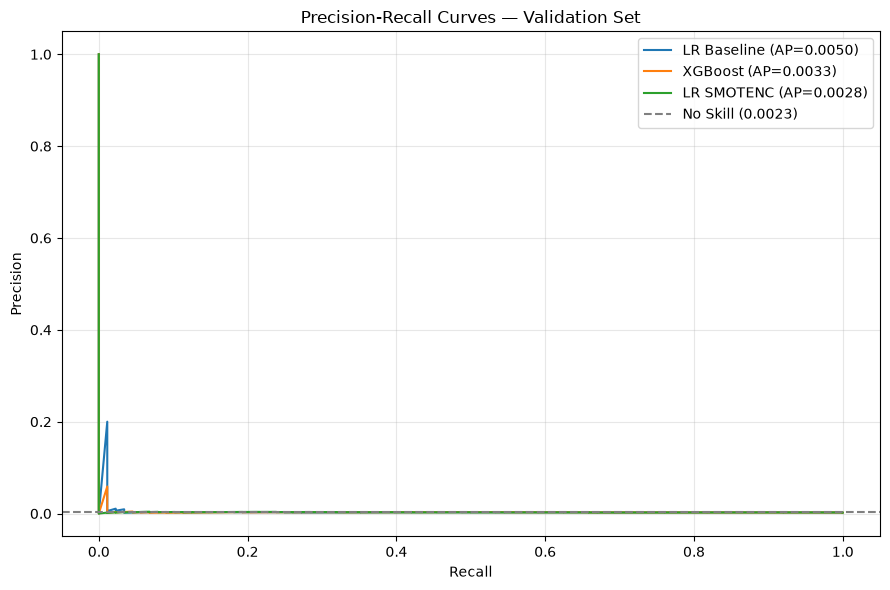

In [33]:
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt

models_to_compare = {
    "LR Baseline": val_prob,
    "XGBoost": xgb_prob,
    "LR SMOTENC": smote_prob
}

plt.figure(figsize=(9, 6))

for name, probabilities in models_to_compare.items():

    precision, recall, thresholds = precision_recall_curve(
        y_val, probabilities
    )

    ap = average_precision_score(y_val, probabilities)

    plt.plot(
        recall,
        precision,
        label=f"{name} (AP={ap:.4f})"
    )

# No-skill baseline
baseline_rate = y_val.mean()

plt.axhline(
    baseline_rate,
    linestyle="--",
    color="gray",
    label=f"No Skill ({baseline_rate:.4f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves — Validation Set")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Finding: Precision-Recall Analysis

All evaluated models show very low precision across
most recall levels.

| Model | Average Precision |
|---|---:|
| Logistic Regression | 0.0050 |
| XGBoost | 0.0033 |
| LR + SMOTENC | 0.0028 |
| No-skill baseline | 0.00235 |

Logistic Regression has the highest Average Precision
among these three models, but its fraud discrimination
remains weak.

**Conclusion:** Oversampling and model complexity have
not substantially improved fraud identification.

The next step is to evaluate operating thresholds and
the resulting fraud detection versus false-positive trade-off.

In [34]:
# Evaluate top-risk transaction groups
from sklearn.metrics import precision_score, recall_score

models = {
    "LR Baseline": val_prob,
    "XGBoost": xgb_prob,
    "LR SMOTENC": smote_prob
}

alert_rates = [0.001, 0.005, 0.01, 0.02, 0.05]

rows = []

for model_name, probabilities in models.items():

    scores = np.asarray(probabilities)
    y_actual = y_val.to_numpy()

    # Rank transactions by fraud score
    ranked_indices = np.argsort(-scores, kind="stable")

    for rate in alert_rates:

        k = max(1, int(np.ceil(len(scores) * rate)))

        predicted = np.zeros(len(scores), dtype=int)
        predicted[ranked_indices[:k]] = 1

        tp = int(((predicted == 1) & (y_actual == 1)).sum())
        fp = int(((predicted == 1) & (y_actual == 0)).sum())

        rows.append({
            "Model": model_name,
            "Alert Rate (%)": rate * 100,
            "Transactions Flagged": k,
            "Frauds Caught": tp,
            "False Positives": fp,
            "Precision (%)": round(
                precision_score(y_actual, predicted, zero_division=0) * 100, 3
            ),
            "Recall (%)": round(
                recall_score(y_actual, predicted) * 100, 2
            )
        })

threshold_analysis = pd.DataFrame(rows)

display(threshold_analysis)

,Model,Alert Rate (%),Transactions Flagged,Frauds Caught,False Positives,Precision (%),Recall (%)
0,LR Baseline,0.1,38,1,37,2.632,1.14
1,LR Baseline,0.5,188,2,186,1.064,2.27
2,LR Baseline,1.0,375,3,372,0.800,3.41
3,LR Baseline,2.0,750,3,747,0.400,3.41
4,LR Baseline,5.0,1875,5,1870,0.267,5.68
5,XGBoost,0.1,38,1,37,2.632,1.14
6,XGBoost,0.5,188,1,187,0.532,1.14
7,XGBoost,1.0,375,1,374,0.267,1.14
8,XGBoost,2.0,750,2,748,0.267,2.27
9,XGBoost,5.0,1875,5,1870,0.267,5.68


### Finding: Top-Risk Transaction Analysis

We compared models by flagging the highest-risk
0.1%, 0.5%, 1%, 2%, and 5% of validation transactions.

At the top 1% alert budget:
- Logistic Regression detected 3 of 88 frauds.
- XGBoost detected 1 of 88 frauds.
- SMOTENC detected 0 of 88 frauds.

At the top 5% alert budget:
- Logistic Regression detected 5 frauds.
- XGBoost detected 5 frauds.
- SMOTENC detected 6 frauds.

**Conclusion:** Increasing the alert budget results in
many false positives with limited fraud detection.

Current models show weak fraud-ranking performance.
Further experiments are required before selecting
a model for the risk decision system.

In [35]:
# XGBoost with class imbalance handling

scale_pos_weight = (
    (y_train == 0).sum() /
    (y_train == 1).sum()
)

print("Scale Pos Weight:", round(scale_pos_weight, 2))

xgb_weighted = Pipeline([
    ("preprocessing", build_preprocessor(False)),
    ("model", XGBClassifier(
        n_estimators=200,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale_pos_weight,
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        random_state=SEED,
        n_jobs=-1
    ))
])

xgb_weighted.fit(X_train, y_train)

xgb_weighted_prob = xgb_weighted.predict_proba(X_val)[:, 1]
xgb_weighted_pred = (xgb_weighted_prob >= 0.5).astype(int)

xgb_weighted_results = {
    "Accuracy": accuracy_score(y_val, xgb_weighted_pred),
    "Precision": precision_score(
        y_val, xgb_weighted_pred, zero_division=0
    ),
    "Recall": recall_score(y_val, xgb_weighted_pred),
    "F1 Score": f1_score(y_val, xgb_weighted_pred),
    "PR-AUC (AP)": average_precision_score(
        y_val, xgb_weighted_prob
    ),
    "ROC-AUC": roc_auc_score(y_val, xgb_weighted_prob)
}

display(pd.DataFrame(
    [xgb_results, xgb_weighted_results],
    index=["XGB Baseline", "XGB Weighted"]
).round(5))

print("\nWeighted XGBoost Confusion Matrix:")
print(confusion_matrix(y_val, xgb_weighted_pred))

Scale Pos Weight: 537.46


,Accuracy,Precision,Recall,F1 Score,PR-AUC (AP),ROC-AUC
XGB Baseline,0.99765,0.0,0.0,0.0,0.00334,0.54243
XGB Weighted,0.98843,0.0,0.0,0.0,0.00229,0.49449



Weighted XGBoost Confusion Matrix:
[[37066   346]
 [   88     0]]


### Finding: XGBoost with Class Weighting

XGBoost was trained using a positive-class weight of 537.46,
calculated from the chronological training partition.

- Fraud detected: 0 of 88
- False positives: 346
- Average Precision: 0.00229
- ROC-AUC: 0.49449

**Conclusion:** Class weighting did not improve XGBoost.
Its fraud ranking deteriorated relative to the baseline.

The available predictors may provide insufficient
information for reliable fraud identification.

In [36]:
from sklearn.metrics import average_precision_score

rng = np.random.default_rng(SEED)

random_ap = []

for _ in range(200):
    random_scores = rng.random(len(y_val))

    random_ap.append(
        average_precision_score(y_val, random_scores)
    )

print("Random AP Mean:", round(np.mean(random_ap), 6))
print("Random AP Std:", round(np.std(random_ap), 6))
print("Random AP 95th Percentile:",
      round(np.percentile(random_ap, 95), 6))

print("Best Model AP:",
      round(average_precision_score(y_val, val_prob), 6))

Random AP Mean: 0.002637
Random AP Std: 0.00067
Random AP 95th Percentile: 0.003649
Best Model AP: 0.004982


### Finding: Random Baseline Comparison

A simulation of 200 random fraud rankings produced:

- Mean AP: 0.002637
- AP standard deviation: 0.000670
- 95th percentile: 0.003649

Logistic Regression achieved an AP of 0.004982,
approximately 1.89 times the simulated random mean.

**Conclusion:** Logistic Regression shows a small
ranking advantage over random predictions, but the
absolute performance remains very weak.

This comparison is exploratory and does not establish
statistically significant or operationally useful
fraud detection.

In [37]:
from sklearn.base import clone
from sklearn.metrics import average_precision_score

rng = np.random.default_rng(SEED)
permuted_ap = []

for i in range(20):
    shuffled_y = rng.permutation(y_train.to_numpy())

    model = clone(lr_baseline)
    model.fit(X_train, shuffled_y)

    probabilities = model.predict_proba(X_val)[:, 1]

    ap = average_precision_score(y_val, probabilities)
    permuted_ap.append(ap)

print("Original LR AP:", round(
    average_precision_score(y_val, val_prob), 6
))

print("Permuted AP Mean:", round(np.mean(permuted_ap), 6))
print("Permuted AP Maximum:", round(np.max(permuted_ap), 6))

print("Permuted AP Values:")
print(np.round(permuted_ap, 6))

Original LR AP: 0.004982
Permuted AP Mean: 0.002652
Permuted AP Maximum: 0.003512
Permuted AP Values:
[0.002712 0.002548 0.002653 0.002486 0.002483 0.002351 0.002229 0.002824
 0.002052 0.002217 0.003512 0.002919 0.002603 0.003217 0.002665 0.002558
 0.002645 0.002813 0.002679 0.002883]


### Finding: Label Permutation Diagnostic

The original Logistic Regression model achieved an
Average Precision of 0.004982.

Across 20 models trained with shuffled fraud labels:
- Mean AP: 0.002652
- Maximum AP: 0.003512
- No permutation exceeded the original model.

**Conclusion:** The original model demonstrates a small
advantage over the shuffled-label models, suggesting
some predictive signal.

However, this exploratory test is not sufficient to
establish reliable or operationally useful fraud detection.

In [38]:
# Consolidate supervised model results

model_results = {
    "LR Baseline": results,
    "LR Weighted": weighted_results,
    "LR Engineered": engineered_results,
    "LR SMOTENC": smote_results,
    "RF Baseline": rf_results,
    "RF Weighted": rf_weighted_results,
    "XGB Baseline": xgb_results,
    "XGB Weighted": xgb_weighted_results
}

model_comparison = pd.DataFrame.from_dict(
    model_results,
    orient="index"
)

model_comparison = model_comparison.sort_values(
    "PR-AUC (AP)",
    ascending=False
)

display(model_comparison.round(5))

,Accuracy,Precision,Recall,F1 Score,PR-AUC (AP),ROC-AUC
LR Baseline,0.99765,0.00000,0.00000,0.00000,0.00498,0.52146
LR Engineered,0.99765,0.00000,0.00000,0.00000,0.00425,0.51709
LR Weighted,0.71232,0.00223,0.27273,0.00443,0.00343,0.50989
XGB Baseline,0.99765,0.00000,0.00000,0.00000,0.00334,0.54243
RF Baseline,0.99765,0.00000,0.00000,0.00000,0.00301,0.54532
RF Weighted,0.99760,0.00000,0.00000,0.00000,0.00291,0.50459
LR SMOTENC,0.99763,0.00000,0.00000,0.00000,0.00276,0.53058
XGB Weighted,0.98843,0.00000,0.00000,0.00000,0.00229,0.49449


### Supervised Model Selection

Eight supervised model configurations were evaluated
using the same chronological training and validation sets.

**Provisional model: Logistic Regression (Baseline)**

- Validation AP: 0.00498
- ROC-AUC: 0.52146
- Default-threshold recall: 0%
- Default-threshold precision: 0%

Logistic Regression achieved the highest Average Precision
among the evaluated candidates.

Class weighting and SMOTENC did not consistently improve
ranking performance. Engineered features also failed to
improve the baseline.

**Decision:** Retain Logistic Regression as the provisional
ranking model for downstream risk analysis.

**Limitation:** Its discrimination is weak, and it is not
suitable for deployment without further validation.

The operating threshold will be determined separately
using validation predictions and business cost assumptions.

In [40]:
from pathlib import Path

# Locate project root
project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

model_path = project_root / "models" / "lr_baseline_pipeline.joblib"
scores_path = project_root / "data" / "validation_fraud_scores.csv"

print("Model exists:", model_path.exists())
print("Validation scores exist:", scores_path.exists())

print("\nModel path:", model_path)
print("Scores path:", scores_path)

Model exists: False
Validation scores exist: False

Model path: c:\Users\ASUS\Downloads\Real-Time-Digital-Fraud-Detection-\models\lr_baseline_pipeline.joblib
Scores path: c:\Users\ASUS\Downloads\Real-Time-Digital-Fraud-Detection-\data\validation_fraud_scores.csv


In [41]:
from pathlib import Path
import joblib
import pandas as pd
import numpy as np

# Project root
project_root = Path(
    r"C:\Users\ASUS\Downloads\Real-Time-Digital-Fraud-Detection-"
)

# Create folders if necessary
models_dir = project_root / "models"
data_dir = project_root / "data"

models_dir.mkdir(parents=True, exist_ok=True)
data_dir.mkdir(parents=True, exist_ok=True)

# Save trained Logistic Regression pipeline
model_path = models_dir / "lr_baseline_pipeline.joblib"
joblib.dump(lr_baseline, model_path)

# Save validation predictions
validation_scores = pd.DataFrame({
    "transaction_id": val_df["transaction id"].to_numpy(),
    "actual_fraud": y_val.to_numpy(),
    "fraud_score": np.asarray(val_prob)
})

scores_path = data_dir / "validation_fraud_scores.csv"
validation_scores.to_csv(scores_path, index=False)

# Verify
print("Model saved:", model_path.exists())
print("Validation scores saved:", scores_path.exists())
print("Validation shape:", validation_scores.shape)
print("Fraud count:", validation_scores["actual_fraud"].sum())

display(validation_scores.head())

Model saved: True
Validation scores saved: True
Validation shape: (37500, 3)
Fraud count: 88


,transaction_id,actual_fraud,fraud_score
0,TXN0000190075,0,0.001721
1,TXN0000195457,0,0.002068
2,TXN0000065534,0,0.001724
3,TXN0000030381,0,0.001725
4,TXN0000141372,0,0.001947


In [42]:
# Reload saved artifacts
saved_model = joblib.load(model_path)
saved_scores = pd.read_csv(scores_path)

# Reproduce predictions using the loaded model
reloaded_prob = saved_model.predict_proba(X_val)[:, 1]

# Verify consistency
np.testing.assert_allclose(
    reloaded_prob,
    saved_scores["fraud_score"].to_numpy(),
    rtol=1e-6,
    atol=1e-10
)

assert len(saved_scores) == 37500
assert saved_scores["actual_fraud"].sum() == 88
assert saved_scores["transaction_id"].is_unique
assert saved_scores["fraud_score"].between(0, 1).all()

print("All verification checks passed!")
print("Model successfully reloaded.")
print("Validation predictions match.")
print("Total transactions:", len(saved_scores))
print("Fraud cases:", saved_scores["actual_fraud"].sum())

All verification checks passed!
Model successfully reloaded.
Validation predictions match.
Total transactions: 37500
Fraud cases: 88


In [44]:
import json
from pathlib import Path

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

eda_path = project_root / "notebooks" / "01_UPI_Fraud_EDA.ipynb"

with open(eda_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

for i, cell in enumerate(notebook["cells"]):
    if cell["cell_type"] != "code":
        continue

    source = "".join(cell["source"])

    if any(term in source for term in [
        "read_csv", "to_csv", "upi_eda_ready"
    ]):
        print(f"\n--- Cell {i} ---")
        print(source[:1500])


--- Cell 2 ---
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("C:\\Users\\ASUS\\Downloads\\fradudetectionbank\\21015299-upi_transactions_2024\\upi_transactions 2024.csv")

print("Dataset shape:", df.shape)
display(df.head())

--- Cell 29 ---
# Export EDA-ready dataset

# Remove EDA-only amount band
df_export = df.drop(
    columns=["amount_band"],
    errors="ignore"
).copy()

# Save dataset
df_export.to_csv(
    "upi_eda_ready.csv",
    index=False
)

print("Dataset exported successfully!")
print("Shape:", df_export.shape)
print("Columns:", df_export.columns.tolist())


In [46]:
from pathlib import Path

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

data_path = PROJECT_ROOT / "data" / "upi_transactions 2024.csv"

df = pd.read_csv(data_path)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (250000, 17)


,transaction id,timestamp,transaction type,merchant_category,amount (INR),transaction_status,sender_age_group,receiver_age_group,sender_state,sender_bank,receiver_bank,device_type,network_type,fraud_flag,hour_of_day,day_of_week,is_weekend
0,TXN0000000001,2024-10-08 15:17:28,P2P,Entertainment,868,SUCCESS,26-35,18-25,Delhi,Axis,SBI,Android,4G,0,15,Tuesday,0
1,TXN0000000002,2024-04-11 06:56:00,P2M,Grocery,1011,SUCCESS,26-35,26-35,Uttar Pradesh,ICICI,Axis,iOS,4G,0,6,Thursday,0
2,TXN0000000003,2024-04-02 13:27:18,P2P,Grocery,477,SUCCESS,26-35,36-45,Karnataka,Yes Bank,PNB,Android,4G,0,13,Tuesday,0
3,TXN0000000004,2024-01-07 10:09:17,P2P,Fuel,2784,SUCCESS,26-35,26-35,Delhi,ICICI,PNB,Android,5G,0,10,Sunday,1
4,TXN0000000005,2024-01-23 19:04:23,P2P,Shopping,990,SUCCESS,26-35,18-25,Delhi,Axis,Yes Bank,iOS,WiFi,0,19,Tuesday,0


In [47]:
import pandas as pd
import numpy as np
from pathlib import Path

SEED = 42

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

scores_path = PROJECT_ROOT / "data" / "validation_fraud_scores.csv"

validation_scores = pd.read_csv(scores_path)

print("Shape:", validation_scores.shape)
print("Fraud cases:", validation_scores["actual_fraud"].sum())

display(validation_scores.head())

Shape: (37500, 3)
Fraud cases: 88


,transaction_id,actual_fraud,fraud_score
0,TXN0000190075,0,0.001721
1,TXN0000195457,0,0.002068
2,TXN0000065534,0,0.001724
3,TXN0000030381,0,0.001725
4,TXN0000141372,0,0.001947


In [48]:
from sklearn.ensemble import IsolationForest
from sklearn.base import clone
from sklearn.metrics import average_precision_score, roc_auc_score

# Load the EDA-ready dataset
df = pd.read_csv(
    PROJECT_ROOT / "data" / "upi_eda_ready.csv",
    parse_dates=["timestamp"]
)

# Recreate the same chronological split
df_sorted = df.sort_values(
    ["timestamp", "transaction id"]
).reset_index(drop=True)

n = len(df_sorted)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

train_df = df_sorted.iloc[:train_end].copy()
val_df = df_sorted.iloc[train_end:val_end].copy()

# Reuse the exact 14 baseline features
numeric_features = [
    "amount (INR)", "hour_of_day", "month"
]

categorical_features = [
    "transaction type", "merchant_category",
    "sender_age_group", "receiver_age_group",
    "sender_state", "sender_bank", "receiver_bank",
    "device_type", "network_type", "day_of_week"
]

binary_features = ["is_weekend"]

feature_cols = (
    numeric_features
    + categorical_features
    + binary_features
)

X_train = train_df[feature_cols]
X_val = val_df[feature_cols]
y_val = val_df["fraud_flag"].astype(int)

# Verify alignment with supervised predictions
assert (
    val_df["transaction id"].to_numpy()
    == validation_scores["transaction_id"].to_numpy()
).all(), "Validation order mismatch!"

assert (
    y_val.to_numpy()
    == validation_scores["actual_fraud"].to_numpy()
).all(), "Validation labels mismatch!"

print("Training transactions:", len(X_train))
print("Validation transactions:", len(X_val))
print("Validation frauds:", y_val.sum())
print("Validation alignment: PASSED")

Training transactions: 175000
Validation transactions: 37500
Validation frauds: 88
Validation alignment: PASSED


In [49]:
from sklearn.ensemble import IsolationForest
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=True
    ))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features),
    ("binary", "passthrough", binary_features)
])

# Isolation Forest pipeline
iso_model = Pipeline([
    ("preprocessing", preprocessor),
    ("model", IsolationForest(
        n_estimators=200,
        max_samples=256,
        contamination="auto",
        random_state=SEED,
        n_jobs=-1
    ))
])

# Train only on chronological training features
iso_model.fit(X_train)

# Higher anomaly score = more unusual transaction
iso_train_scores = -iso_model.decision_function(X_train)
iso_val_scores = -iso_model.decision_function(X_val)

print("Isolation Forest trained successfully!")

print("Training scores:", iso_train_scores.shape)
print("Validation scores:", iso_val_scores.shape)

print("\nValidation anomaly score summary:")
display(pd.Series(iso_val_scores).describe())

Isolation Forest trained successfully!
Training scores: (175000,)
Validation scores: (37500,)

Validation anomaly score summary:


count    37500.000000
mean        -0.039986
std          0.017319
min         -0.091240
25%         -0.052493
50%         -0.041426
75%         -0.028855
max          0.055093
dtype: float64

In [50]:
from sklearn.metrics import average_precision_score, roc_auc_score

# Evaluate anomaly ranking
iso_ap = average_precision_score(y_val, iso_val_scores)
iso_roc = roc_auc_score(y_val, iso_val_scores)

print("Isolation Forest AP:", round(iso_ap, 6))
print("Isolation Forest ROC-AUC:", round(iso_roc, 6))

# Evaluate top 1% most anomalous transactions
k = int(np.ceil(len(iso_val_scores) * 0.01))

top_indices = np.argsort(-iso_val_scores)[:k]

y_actual = y_val.to_numpy()

frauds_caught = int(y_actual[top_indices].sum())
false_positives = k - frauds_caught

print("\nTop 1% Anomaly Detection:")
print("Transactions flagged:", k)
print("Frauds caught:", frauds_caught, "out of", int(y_actual.sum()))
print("False positives:", false_positives)
print("Precision:", round(frauds_caught / k, 6))
print("Recall:", round(frauds_caught / y_actual.sum(), 6))

Isolation Forest AP: 0.002339
Isolation Forest ROC-AUC: 0.489961

Top 1% Anomaly Detection:
Transactions flagged: 375
Frauds caught: 1 out of 88
False positives: 374
Precision: 0.002667
Recall: 0.011364


### Finding: Isolation Forest Evaluation

Isolation Forest was trained on 175,000 transactions
without using fraud labels.

Validation results:
- Average Precision: 0.002339
- ROC-AUC: 0.489961
- Top 1% fraud detection: 1 of 88
- False positives: 374

**Conclusion:** Isolation Forest did not outperform
the Logistic Regression baseline.

Its anomaly scores show little evidence of useful
fraud discrimination.

A hybrid score will be evaluated before deciding
whether anomaly detection should contribute to
the final decision engine.

In [52]:
from sklearn.metrics import average_precision_score, roc_auc_score

# Supervised fraud scores
lr_scores = validation_scores["fraud_score"].to_numpy()

# Convert both scores to percentile ranks
lr_rank = pd.Series(lr_scores).rank(pct=True).to_numpy()
iso_rank = pd.Series(iso_val_scores).rank(pct=True).to_numpy()

# Fixed hybrid combinations
hybrid_scores = {
    "LR Only": lr_scores,
    "Isolation Forest Only": iso_val_scores,
    "Hybrid 80% LR + 20% ISO": 0.8 * lr_rank + 0.2 * iso_rank,
    "Hybrid 50% LR + 50% ISO": 0.5 * lr_rank + 0.5 * iso_rank,
    "Hybrid 20% LR + 80% ISO": 0.2 * lr_rank + 0.8 * iso_rank
}

y_actual = y_val.to_numpy()
k = int(np.ceil(len(y_actual) * 0.01))

rows = []

for name, scores in hybrid_scores.items():

    ap = average_precision_score(y_actual, scores)
    roc = roc_auc_score(y_actual, scores)

    top_indices = np.argsort(-scores, kind="stable")[:k]
    caught = int(y_actual[top_indices].sum())

    rows.append({
        "Model": name,
        "PR-AUC (AP)": round(ap, 6),
        "ROC-AUC": round(roc, 6),
        "Top 1% Fraud Caught": caught,
        "Top 1% False Positives": k - caught
    })

hybrid_comparison = pd.DataFrame(rows)

display(
    hybrid_comparison.sort_values(
        "PR-AUC (AP)", ascending=False
    )
)

,Model,PR-AUC (AP),ROC-AUC,Top 1% Fraud Caught,Top 1% False Positives
2,Hybrid 80% LR + 20% ISO,0.014000,0.516346,2,373
3,Hybrid 50% LR + 50% ISO,0.006302,0.505361,2,373
0,LR Only,0.004982,0.521464,3,372
4,Hybrid 20% LR + 80% ISO,0.002957,0.495379,1,374
1,Isolation Forest Only,0.002339,0.489961,1,374


### Finding: Hybrid Risk Score Evaluation

The 80% Logistic Regression + 20% Isolation Forest
hybrid achieved the highest validation Average Precision
(AP = 0.01400).

However, it detected only 2 of 88 fraud cases in the
top 1% of transactions, compared with 3 for LR alone.

The improvement in AP did not translate into better
detection at the evaluated 1% alert budget.

**Decision:** Retain both LR and the 80/20 hybrid
as candidates for cost-based threshold evaluation.

The hybrid score is a ranking score, not a calibrated
fraud probability.

In [53]:
# Compare LR and hybrid at different alert budgets

candidate_scores = {
    "Logistic Regression": lr_scores,
    "Hybrid 80% LR + 20% ISO": hybrid_scores[
        "Hybrid 80% LR + 20% ISO"
    ]
}

alert_rates = [0.001, 0.005, 0.01, 0.02, 0.05, 0.10]

comparison_rows = []

for model_name, scores in candidate_scores.items():

    scores = np.asarray(scores)

    for alert_rate in alert_rates:

        k = int(np.ceil(len(scores) * alert_rate))

        top_indices = np.argsort(
            -scores, kind="stable"
        )[:k]

        tp = int(y_actual[top_indices].sum())
        fp = k - tp
        fn = int(y_actual.sum()) - tp

        comparison_rows.append({
            "Model": model_name,
            "Alert Rate (%)": alert_rate * 100,
            "Transactions Flagged": k,
            "Frauds Caught": tp,
            "False Positives": fp,
            "Missed Frauds": fn,
            "Precision (%)": round(100 * tp / k, 3),
            "Recall (%)": round(
                100 * tp / y_actual.sum(), 2
            )
        })

budget_comparison = pd.DataFrame(comparison_rows)

display(budget_comparison)

,Model,Alert Rate (%),Transactions Flagged,Frauds Caught,False Positives,Missed Frauds,Precision (%),Recall (%)
0,Logistic Regression,0.1,38,1,37,87,2.632,1.14
1,Logistic Regression,0.5,188,2,186,86,1.064,2.27
2,Logistic Regression,1.0,375,3,372,85,0.800,3.41
3,Logistic Regression,2.0,750,3,747,85,0.400,3.41
4,Logistic Regression,5.0,1875,5,1870,83,0.267,5.68
5,Logistic Regression,10.0,3750,10,3740,78,0.267,11.36
6,Hybrid 80% LR + 20% ISO,0.1,38,1,37,87,2.632,1.14
7,Hybrid 80% LR + 20% ISO,0.5,188,2,186,86,1.064,2.27
8,Hybrid 80% LR + 20% ISO,1.0,375,2,373,86,0.533,2.27
9,Hybrid 80% LR + 20% ISO,2.0,750,3,747,85,0.400,3.41


### Finding: Operational Alert Budget Comparison

Logistic Regression and the 80/20 hybrid were compared
at alert budgets ranging from 0.1% to 10%.

Logistic Regression detected more fraud at the 1% and
5% budgets, while both approaches performed equally
at the other tested budgets.

At a 5% alert budget:
- Fraud detected: 5 of 88
- False positives: 1,870
- Missed frauds: 83

**Decision:** Retain Logistic Regression as the
provisional scoring model.

The hybrid approach remains experimental because its
higher Average Precision did not produce consistently
better operational detection.

In [54]:
# Step 8: Three-level risk decision engine

risk_scores = validation_scores["fraud_score"].to_numpy()
y_actual = validation_scores["actual_fraud"].to_numpy()

# Use rankings to enforce exact validation alert budgets
ranked_indices = np.argsort(-risk_scores, kind="stable")

n = len(risk_scores)
block_count = int(np.ceil(n * 0.01))
challenge_count = int(np.ceil(n * 0.05))

decisions = np.full(n, "APPROVE", dtype=object)

# Highest 5% receive extra scrutiny
decisions[ranked_indices[:challenge_count]] = "OTP"

# Highest 1% are assigned simulated BLOCK decisions
decisions[ranked_indices[:block_count]] = "BLOCK"

validation_decisions = validation_scores.copy()
validation_decisions["decision"] = decisions

decision_summary = (
    validation_decisions
    .groupby("decision")
    .agg(
        transactions=("transaction_id", "count"),
        actual_frauds=("actual_fraud", "sum")
    )
    .reindex(["APPROVE", "OTP", "BLOCK"])
)

decision_summary["genuine_transactions"] = (
    decision_summary["transactions"]
    - decision_summary["actual_frauds"]
)

decision_summary["fraud_rate_%"] = (
    100 * decision_summary["actual_frauds"]
    / decision_summary["transactions"]
)

display(decision_summary.round(3))

print("\nTotal transactions:",
      decision_summary["transactions"].sum())

print("Total frauds:",
      decision_summary["actual_frauds"].sum())

,transactions,actual_frauds,genuine_transactions,fraud_rate_%
decision,,,,
APPROVE,35625,83,35542,0.233
OTP,1500,2,1498,0.133
BLOCK,375,3,372,0.800



Total transactions: 37500
Total frauds: 88


In [55]:
# Step 9: Illustrative business cost comparison

COST_MISSED_FRAUD = 5000
COST_OTP = 5
COST_FALSE_BLOCK = 500

df_cost = validation_decisions.copy()

# Cost per transaction under our simulated policy
df_cost["cost"] = 0.0

# Fraud approved or sent to OTP:
# conservatively treated as an unprevented fraud
missed_fraud_mask = (
    (df_cost["actual_fraud"] == 1)
    & (df_cost["decision"] != "BLOCK")
)

df_cost.loc[missed_fraud_mask, "cost"] += COST_MISSED_FRAUD

# OTP verification cost for everyone challenged
df_cost.loc[
    df_cost["decision"] == "OTP", "cost"
] += COST_OTP

# Cost of blocking a genuine transaction
false_block_mask = (
    (df_cost["decision"] == "BLOCK")
    & (df_cost["actual_fraud"] == 0)
)

df_cost.loc[false_block_mask, "cost"] += COST_FALSE_BLOCK

# Total cost of risk decision policy
policy_cost = df_cost["cost"].sum()

# Baseline: approve every transaction
approve_all_cost = (
    df_cost["actual_fraud"].sum()
    * COST_MISSED_FRAUD
)

cost_comparison = pd.DataFrame({
    "Policy": [
        "Approve All",
        "Approve / OTP / Block"
    ],
    "Estimated Cost (INR)": [
        approve_all_cost,
        policy_cost
    ]
})

display(cost_comparison)

print("Estimated savings (INR):",
      approve_all_cost - policy_cost)

print("Cost reduction (%):",
      round(
          100 * (approve_all_cost - policy_cost)
          / approve_all_cost,
          2
      ))

,Policy,Estimated Cost (INR)
0,Approve All,440000.0
1,Approve / OTP / Block,618500.0


Estimated savings (INR): -178500.0
Cost reduction (%): -40.57


### Finding: Cost-Based Risk Policy Evaluation

The initial Approve / OTP / Block policy was evaluated
using illustrative business costs.

| Policy | Estimated Cost |
|---|---:|
| Approve All | ₹4,40,000 |
| Approve / OTP / Block | ₹6,18,500 |

The proposed policy increases estimated costs by
₹1,78,500 (40.57%).

It prevents only 3 fraudulent transactions while
incorrectly blocking 372 genuine transactions.

**Conclusion:** The proposed 1% blocking policy is not
cost-effective under the assumed penalties.

Alternative policies should be evaluated before
selecting a final risk decision strategy.

In [56]:
# Step 10: Compare alternative decision policies

policy_options = [
    ("Approve All", 0.0, 0.0),
    ("OTP Top 1%", 0.0, 0.01),
    ("OTP Top 5%", 0.0, 0.05),
    ("Block Top 0.1%", 0.001, 0.001),
    ("Block 0.1% + OTP 1%", 0.001, 0.01),
    ("Block 0.1% + OTP 5%", 0.001, 0.05),
    ("Block 0.5% + OTP 5%", 0.005, 0.05),
    ("Block 1% + OTP 5%", 0.01, 0.05)
]

risk_scores = validation_scores["fraud_score"].to_numpy()
labels = validation_scores["actual_fraud"].to_numpy()

ranking = np.argsort(-risk_scores, kind="stable")
n = len(labels)

policy_rows = []

for policy_name, block_rate, review_rate in policy_options:

    block_n = int(np.ceil(n * block_rate))
    review_n = int(np.ceil(n * review_rate))

    decisions = np.full(n, "APPROVE", dtype=object)

    decisions[ranking[:review_n]] = "OTP"
    decisions[ranking[:block_n]] = "BLOCK"

    approved_frauds = int(
        ((decisions == "APPROVE") & (labels == 1)).sum()
    )

    otp_frauds = int(
        ((decisions == "OTP") & (labels == 1)).sum()
    )

    blocked_frauds = int(
        ((decisions == "BLOCK") & (labels == 1)).sum()
    )

    false_blocks = int(
        ((decisions == "BLOCK") & (labels == 0)).sum()
    )

    otp_count = int((decisions == "OTP").sum())

    # Conservative: OTP does not prevent fraud in this simulation
    unprevented_frauds = approved_frauds + otp_frauds

    estimated_cost = (
        unprevented_frauds * COST_MISSED_FRAUD
        + otp_count * COST_OTP
        + false_blocks * COST_FALSE_BLOCK
    )

    policy_rows.append({
        "Policy": policy_name,
        "Blocked Frauds": blocked_frauds,
        "False Blocks": false_blocks,
        "OTP Challenges": otp_count,
        "Estimated Cost (INR)": estimated_cost
    })

policy_comparison = pd.DataFrame(policy_rows)

display(
    policy_comparison.sort_values("Estimated Cost (INR)")
)

,Policy,Blocked Frauds,False Blocks,OTP Challenges,Estimated Cost (INR)
0,Approve All,0,0,0,440000
1,OTP Top 1%,0,0,375,441875
2,OTP Top 5%,0,0,1875,449375
3,Block Top 0.1%,1,37,0,453500
4,Block 0.1% + OTP 1%,1,37,337,455185
5,Block 0.1% + OTP 5%,1,37,1837,462685
6,Block 0.5% + OTP 5%,2,186,1687,531435
7,Block 1% + OTP 5%,3,372,1500,618500


### Finding: Cost-Based Policy Comparison

Eight decision policies were evaluated using
illustrative costs.

The lowest-cost policy was Approve All (₹4,40,000).

The most conservative blocking policy, Block Top 0.1%,
cost ₹4,53,500 and prevented only one fraud while
blocking 37 genuine transactions.

**Conclusion:** None of the tested intervention policies
outperformed Approve All under the current assumptions.

The ML model is insufficiently discriminative to
justify automatic blocking.

A three-level Approve / OTP / Block policy will be
retained for demonstration only, not recommended
for real-world deployment.

In [57]:
# Step 11: Derive fixed thresholds from validation scores

risk_scores = validation_scores["fraud_score"].to_numpy()

# Thresholds estimated from validation data only
OTP_THRESHOLD = float(np.quantile(risk_scores, 0.95))
BLOCK_THRESHOLD = float(np.quantile(risk_scores, 0.99))

assert OTP_THRESHOLD < BLOCK_THRESHOLD

def assign_risk_decision(score):
    if score >= BLOCK_THRESHOLD:
        return "BLOCK"
    elif score >= OTP_THRESHOLD:
        return "OTP"
    return "APPROVE"

# Apply fixed thresholds to validation transactions
validation_decisions_fixed = validation_scores.copy()

validation_decisions_fixed["decision"] = (
    validation_decisions_fixed["fraud_score"]
    .apply(assign_risk_decision)
)

# Summarize decisions
fixed_summary = (
    validation_decisions_fixed
    .groupby("decision")
    .agg(
        transactions=("transaction_id", "count"),
        frauds=("actual_fraud", "sum")
    )
    .reindex(["APPROVE", "OTP", "BLOCK"], fill_value=0)
)

fixed_summary["genuine"] = (
    fixed_summary["transactions"] - fixed_summary["frauds"]
)

print("OTP Threshold:", round(OTP_THRESHOLD, 8))
print("BLOCK Threshold:", round(BLOCK_THRESHOLD, 8))

display(fixed_summary)

# Test the reusable function
sample_score = float(validation_scores["fraud_score"].iloc[0])

print("\nSample fraud score:", sample_score)
print("Decision:", assign_risk_decision(sample_score))

OTP Threshold: 0.00268486
BLOCK Threshold: 0.00354331


,transactions,frauds,genuine
decision,,,
APPROVE,35625,83,35542
OTP,1500,2,1498
BLOCK,375,3,372



Sample fraud score: 0.0017205474921904
Decision: APPROVE


In [58]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
    confusion_matrix
)
import joblib
import numpy as np
import pandas as pd

# 1. Recreate untouched chronological test partition
test_df = df_sorted.iloc[val_end:].copy()

X_test = test_df[feature_cols]
y_test = test_df["fraud_flag"].astype(int).to_numpy()

# 2. Load the selected supervised model
model_path = (
    PROJECT_ROOT / "models" / "lr_baseline_pipeline.joblib"
)

final_model = joblib.load(model_path)

# 3. Generate test fraud scores
test_prob = final_model.predict_proba(X_test)[:, 1]

# 4. Apply FROZEN validation thresholds
test_decisions = np.array([
    assign_risk_decision(float(score))
    for score in test_prob
])

# 5. Default-threshold classification metrics
test_pred_05 = (test_prob >= 0.5).astype(int)

test_metrics = {
    "Accuracy": accuracy_score(y_test, test_pred_05),
    "Precision": precision_score(
        y_test, test_pred_05, zero_division=0
    ),
    "Recall": recall_score(y_test, test_pred_05),
    "F1 Score": f1_score(
        y_test, test_pred_05, zero_division=0
    ),
    "PR-AUC (AP)": average_precision_score(y_test, test_prob),
    "ROC-AUC": roc_auc_score(y_test, test_prob)
}

print("FINAL TEST METRICS (threshold = 0.5)")
display(pd.DataFrame([test_metrics]).round(6))

print("\nDefault-threshold confusion matrix:")
print(confusion_matrix(y_test, test_pred_05))

# 6. Evaluate the three-level decision engine
test_results = pd.DataFrame({
    "transaction_id": test_df["transaction id"].to_numpy(),
    "actual_fraud": y_test,
    "fraud_score": test_prob,
    "decision": test_decisions
})

test_decision_summary = (
    test_results.groupby("decision")
    .agg(
        transactions=("transaction_id", "count"),
        frauds=("actual_fraud", "sum")
    )
    .reindex(["APPROVE", "OTP", "BLOCK"], fill_value=0)
)

test_decision_summary["genuine"] = (
    test_decision_summary["transactions"]
    - test_decision_summary["frauds"]
)

print("\nFINAL TEST DECISION SUMMARY")
display(test_decision_summary)

print("\nTotal test transactions:", len(test_results))
print("Total test frauds:", y_test.sum())

# 7. Evaluate illustrative business cost on test data
test_missed_frauds = int(
    test_results.loc[
        test_results["decision"] != "BLOCK",
        "actual_fraud"
    ].sum()
)

test_false_blocks = int(
    (
        (test_results["decision"] == "BLOCK")
        & (test_results["actual_fraud"] == 0)
    ).sum()
)

test_otp_count = int(
    (test_results["decision"] == "OTP").sum()
)

test_policy_cost = (
    test_missed_frauds * COST_MISSED_FRAUD
    + test_false_blocks * COST_FALSE_BLOCK
    + test_otp_count * COST_OTP
)

test_approve_all_cost = int(y_test.sum()) * COST_MISSED_FRAUD

print("\nILLUSTRATIVE TEST COST COMPARISON")
print("Approve All Cost:", test_approve_all_cost)
print("Risk Policy Cost:", test_policy_cost)
print("Difference:", test_policy_cost - test_approve_all_cost)

FINAL TEST METRICS (threshold = 0.5)


,Accuracy,Precision,Recall,F1 Score,PR-AUC (AP),ROC-AUC
0,0.998213,0.0,0.0,0.0,0.002361,0.536582



Default-threshold confusion matrix:
[[37433     0]
 [   67     0]]

FINAL TEST DECISION SUMMARY


,transactions,frauds,genuine
decision,,,
APPROVE,36112,62,36050
OTP,1097,5,1092
BLOCK,291,0,291



Total test transactions: 37500
Total test frauds: 67

ILLUSTRATIVE TEST COST COMPARISON
Approve All Cost: 335000
Risk Policy Cost: 485985
Difference: 150985


In [59]:
import json
from pathlib import Path

# Save fixed thresholds and policy metadata
risk_config = {
    "model": "Logistic Regression Baseline",
    "otp_threshold": OTP_THRESHOLD,
    "block_threshold": BLOCK_THRESHOLD,
    "score_type": "uncalibrated_fraud_score",
    "policy_type": "demonstration_only",
    "cost_missed_fraud": COST_MISSED_FRAUD,
    "cost_otp": COST_OTP,
    "cost_false_block": COST_FALSE_BLOCK
}

config_path = PROJECT_ROOT / "models" / "risk_config.json"

with open(config_path, "w", encoding="utf-8") as f:
    json.dump(risk_config, f, indent=4)

# Save test predictions locally
test_path = PROJECT_ROOT / "data" / "test_fraud_decisions.csv"
test_results.to_csv(test_path, index=False)

print("Risk configuration saved:", config_path.exists())
print("Test predictions saved:", test_path.exists())
print("Test shape:", test_results.shape)

Risk configuration saved: True
Test predictions saved: True
Test shape: (37500, 4)


In [60]:
import json
import joblib
import pandas as pd

# Load saved model
fraud_model = joblib.load(
    PROJECT_ROOT / "models" / "lr_baseline_pipeline.joblib"
)

# Load saved thresholds
with open(
    PROJECT_ROOT / "models" / "risk_config.json",
    "r",
    encoding="utf-8"
) as f:
    config = json.load(f)

def predict_transaction(transaction):
    # Convert one transaction to a DataFrame
    input_df = pd.DataFrame([transaction])

    # Ensure exactly the required model features
    input_df = input_df[feature_cols]

    # Generate fraud score
    score = float(
        fraud_model.predict_proba(input_df)[0, 1]
    )

    # Apply fixed thresholds
    if score >= config["block_threshold"]:
        decision = "BLOCK"
    elif score >= config["otp_threshold"]:
        decision = "OTP"
    else:
        decision = "APPROVE"

    return {
        "fraud_score": round(score, 8),
        "decision": decision,
        "policy": "DEMONSTRATION ONLY"
    }

# Test using a real feature row from our held-out dataset
sample_transaction = X_test.iloc[0].to_dict()

prediction = predict_transaction(sample_transaction)

print("Sample prediction:", prediction)

Sample prediction: {'fraud_score': 0.00137866, 'decision': 'APPROVE', 'policy': 'DEMONSTRATION ONLY'}
